# Exploratory data analysis: Penmanshiel

Penmanshiel is a 14-turbine onshore wind farm in the Scottish Borders (Senvion MM82, 2.05 MW each; there is no turbine 03). The data are the Greenbyte exports released as open data, converted to Parquet by `python penmanshiel_process.py`:

| File | Contents |
|---|---|
| `turbines.parquet` | static metadata, one row per turbine |
| `feature_description.parquet` | SCADA column name -> original label, signal, stat, unit |
| `scada/<turbine_id>.parquet` | 10-minute SCADA, 2016-06 to 2023-12 |
| `status/<turbine_id>.parquet` | status / event log |

Unlike CARE to Compare there are **no fault labels**. The status log is the only event record, so this notebook looks at what it contains and how far it can stand in for labels.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display

DATA = Path("data/Penmanshiel")
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

# Same categorical palette as eda.ipynb (colour-blind-checked), used in fixed order.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#e6e5e0", "#b5b4ad"


def style_ax(ax, grid_axis="both"):
    # Recessive grid and axes, as in eda.ipynb.
    if grid_axis:
        ax.grid(True, axis=grid_axis, color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.title.set_color(INK)


turbines = pd.read_parquet(DATA / "turbines.parquet")
features = pd.read_parquet(DATA / "feature_description.parquet")
TURBINE_IDS = turbines["turbine_id"].tolist()
label = lambda t: f"T{t:02d}"
status = pd.concat([pd.read_parquet(DATA / "status" / f"{t}.parquet") for t in TURBINE_IDS], ignore_index=True)
print(f"{len(turbines)} turbines, {features['column'].nunique()} SCADA columns, {len(status):,} status rows")

14 turbines, 372 SCADA columns, 999,881 status rows


## Static data

One row per turbine from `Penmanshiel_WT_static.csv`. All turbines are the same model and rating and share one commercial operations date. They differ only in position and ground elevation.

In [2]:
turbines

,turbine_id,wind_farm,title,alternative_title,identity,manufacturer,model,rated_power_kw,hub_height_m,rotor_diameter_m,latitude,longitude,elevation_m,country,commercial_operations_date
0,1,Penmanshiel,Penmanshiel 01,T01,MM82/59 82765-01,Senvion,MM82,2050.0,59.0,82.0,55.902502,-2.306389,212.26,UK,2016-09-01
1,2,Penmanshiel,Penmanshiel 02,T02,MM82/59 82766-02,Senvion,MM82,2050.0,59.0,82.0,55.900008,-2.301268,200.46,UK,2016-09-01
2,4,Penmanshiel,Penmanshiel 04,T04,MM82/59 82768-04,Senvion,MM82,2050.0,59.0,82.0,55.905943,-2.302690,208.91,UK,2016-09-01
3,5,Penmanshiel,Penmanshiel 05,T05,MM82/59 82769-05,Senvion,MM82,2050.0,59.0,82.0,55.903294,-2.298367,201.38,UK,2016-09-01
4,6,Penmanshiel,Penmanshiel 06,T06,MM82/59 82770-06,Senvion,MM82,2050.0,59.0,82.0,55.900951,-2.293967,199.03,UK,2016-09-01
5,7,Penmanshiel,Penmanshiel 07,T07,MM82/59 82771-07,Senvion,MM82,2050.0,59.0,82.0,55.898741,-2.289856,180.24,UK,2016-09-01
6,8,Penmanshiel,Penmanshiel 08,T08,MM82/59 82772-08,Senvion,MM82,2050.0,59.0,82.0,55.907915,-2.297314,200.13,UK,2016-09-01
7,9,Penmanshiel,Penmanshiel 09,T09,MM82/59 82773-09,Senvion,MM82,2050.0,59.0,82.0,55.904990,-2.291806,187.04,UK,2016-09-01
8,10,Penmanshiel,Penmanshiel 10,T10,MM82/59 82774-10,Senvion,MM82,2050.0,59.0,82.0,55.903032,-2.287585,186.88,UK,2016-09-01
9,11,Penmanshiel,Penmanshiel 11,T11,MM82/59 82775-11,Senvion,MM82,2050.0,59.0,82.0,55.900852,-2.282371,204.84,UK,2016-09-01


In [3]:
varying = [c for c in turbines.columns if turbines[c].nunique() > 1]
constant = {c: turbines[c].iloc[0] for c in turbines.columns if turbines[c].nunique() == 1}
print("Same for every turbine:")
for k, v in constant.items():
    print(f"  {k:28} {v}")
print("\nVaries:", varying)
turbines[["elevation_m"]].describe().T.round(1)

Same for every turbine:
  wind_farm                    Penmanshiel
  manufacturer                 Senvion
  model                        MM82
  rated_power_kw               2050.0
  hub_height_m                 59.0
  rotor_diameter_m             82.0
  country                      UK
  commercial_operations_date   2016-09-01 00:00:00

Varies: ['turbine_id', 'title', 'alternative_title', 'identity', 'latitude', 'longitude', 'elevation_m']


,count,mean,std,min,25%,50%,75%,max
elevation_m,14.0,204.9,14.1,180.2,199.3,203.1,217.5,228.2


### Layout

Turbine positions, with ground elevation as a single-hue scale (darker = higher). Axes are scaled so 1 km is the same length in both directions. The prevailing wind in the UK is south-westerly, so turbines to the north-east sit in the wake of others for much of the time. That matters when comparing turbines' power curves.

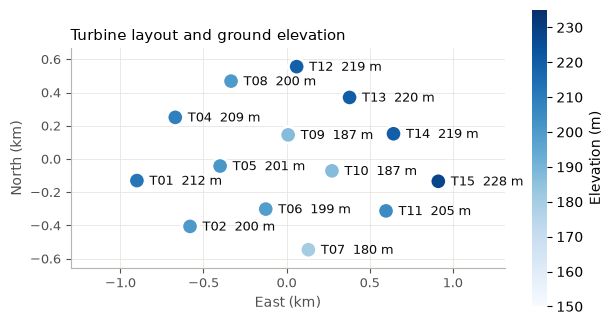

Nearest-neighbour spacing: 4.2 to 5.1 rotor diameters (median 4.4)


In [4]:
lat0 = np.deg2rad(turbines["latitude"].mean())
x_km = (turbines["longitude"] - turbines["longitude"].mean()) * 111.32 * np.cos(lat0)
y_km = (turbines["latitude"] - turbines["latitude"].mean()) * 110.57

fig, ax = plt.subplots(figsize=(7, 5.5))
sc = ax.scatter(x_km, y_km, c=turbines["elevation_m"], cmap="Blues", vmin=150, vmax=235, s=140,
                edgecolor="white", linewidth=2, zorder=3)
for x, y, t, e in zip(x_km, y_km, turbines["turbine_id"], turbines["elevation_m"]):
    ax.annotate(f"{label(t)}  {e:.0f} m", (x, y), xytext=(9, -3), textcoords="offset points",
                fontsize=9, color=INK)
ax.set_aspect("equal")
ax.margins(x=0.22, y=0.1)  # room for the labels
ax.set_xlabel("East (km)", color=MUTED)
ax.set_ylabel("North (km)", color=MUTED)
ax.set_title("Turbine layout and ground elevation", loc="left", fontsize=11)
cb = fig.colorbar(sc, ax=ax, shrink=0.7, label="Elevation (m)")
cb.outline.set_visible(False)
style_ax(ax)
plt.show()

# Nearest-neighbour spacing in rotor diameters
xy = np.c_[x_km, y_km]
d = np.sqrt(((xy[:, None] - xy[None]) ** 2).sum(-1)) * 1000 / turbines["rotor_diameter_m"].iloc[0]
np.fill_diagonal(d, np.inf)
print(f"Nearest-neighbour spacing: {d.min(1).min():.1f} to {d.min(1).max():.1f} rotor diameters "
      f"(median {np.median(d.min(1)):.1f})")

## Turbines: SCADA coverage

Monthly share of 10-minute slots in which each turbine reported active power. Light cells are months with gaps; white is no data at all. T01–T10 have no export for January 2023. The farm was commissioned in mid-2016 (commercial operations from September), so the first months are partial.

In [5]:
cov_rows, summary = [], []
for t in TURBINE_IDS:
    d = pd.read_parquet(DATA / "scada" / f"{t}.parquet", columns=["time_stamp", "power", "wind_speed"])
    ok = d.set_index("time_stamp")["power"].notna()
    monthly = ok.resample("MS").sum()
    slots = monthly.index.days_in_month * 144
    cov_rows.append((monthly / slots).rename(label(t)))
    summary.append({"turbine": label(t), "first": d["time_stamp"].min(), "last": d["time_stamp"].max(),
                    "rows": len(d), "power_missing_%": 100 * d["power"].isna().mean(),
                    "wind_speed_missing_%": 100 * d["wind_speed"].isna().mean(),
                    "mean_power_kW": d["power"].mean()})
coverage = pd.concat(cov_rows, axis=1).T
scada_summary = pd.DataFrame(summary).set_index("turbine")
scada_summary.round({"power_missing_%": 1, "wind_speed_missing_%": 1, "mean_power_kW": 0})

,first,last,rows,power_missing_%,wind_speed_missing_%,mean_power_kW
turbine,,,,,,
T01,2016-06-06 18:10:00,2023-12-31 23:50:00,393587,1.3,1.3,661.0
T02,2016-06-03 08:50:00,2023-12-31 23:50:00,394075,1.6,1.7,628.0
T04,2016-06-13 14:50:00,2023-12-31 23:50:00,392599,1.3,1.3,642.0
T05,2016-06-15 18:50:00,2023-12-31 23:50:00,392287,1.2,1.3,604.0
T06,2016-06-02 18:00:00,2023-12-31 23:50:00,394164,1.9,1.9,602.0
T07,2016-06-02 17:40:00,2023-12-31 23:50:00,394166,1.8,1.8,549.0
T08,2016-07-27 15:40:00,2023-12-31 23:50:00,386258,1.8,1.8,612.0
T09,2016-06-24 11:40:00,2023-12-31 23:50:00,391034,3.1,3.1,539.0
T10,2016-06-27 18:00:00,2023-12-31 23:50:00,390564,3.3,4.4,527.0


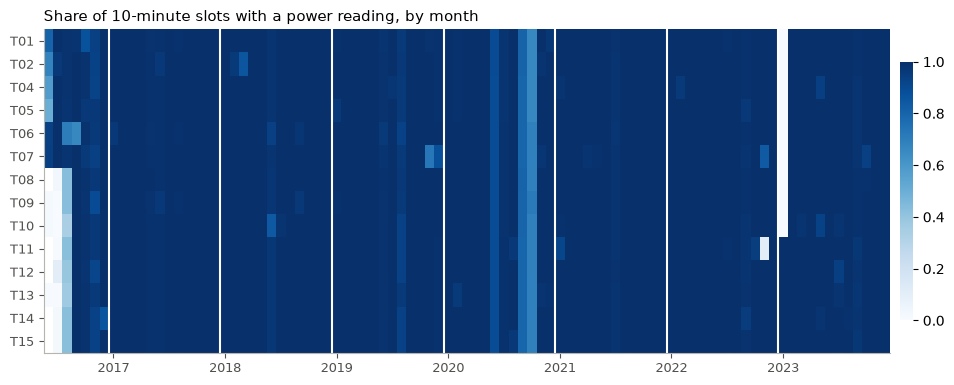

85 turbine-months below 90% coverage (excluding months with no data at all)


,turbine,time_stamp,coverage
5,T01,2023-01-01,0.00
11,T02,2023-01-01,0.00
21,T05,2023-01-01,0.00
16,T04,2023-01-01,0.00
27,T06,2023-01-01,0.00
42,T09,2016-07-01,0.00
40,T08,2023-01-01,0.00
34,T07,2023-01-01,0.00
48,T09,2023-01-01,0.00
50,T10,2016-07-01,0.00


In [6]:
fig, ax = plt.subplots(figsize=(13, 4.2))
months = coverage.columns
im = ax.imshow(coverage.to_numpy(dtype=float), aspect="auto", cmap="Blues", vmin=0, vmax=1, interpolation="none")
ax.set_yticks(range(len(coverage)), coverage.index)
year_starts = [i for i, m in enumerate(months) if m.month == 1]
ax.set_xticks(year_starts, [months[i].year for i in year_starts])
for i in year_starts:
    ax.axvline(i - 0.5, color="white", lw=1.5)
ax.set_title("Share of 10-minute slots with a power reading, by month", loc="left", fontsize=11)
cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.01)
cb.outline.set_visible(False)
style_ax(ax, grid_axis=None)
plt.show()

low = coverage.stack()
low = low[low < 0.9].rename("coverage").reset_index().rename(columns={"level_0": "turbine", "level_1": "month"})
print(f"{len(low)} turbine-months below 90% coverage (excluding months with no data at all)")
low.sort_values("coverage").head(20).round({"coverage": 2})

## SCADA signals

`feature_description` lists all 372 columns. Each signal has its 10-minute mean (`stat` empty) and usually `min`, `max` and `std`. Many columns are availability and energy-accounting counters rather than sensor readings, and some only exist in the 2023 exports. Share of non-null values per column (T01, whole period) comes from the Parquet metadata, so no data is loaded.

In [7]:
def non_null_share(path):
    meta = pq.ParquetFile(path).metadata
    nulls = {meta.schema.column(j).name: 0 for j in range(meta.num_columns)}
    for i in range(meta.num_row_groups):
        rg = meta.row_group(i)
        for j in range(rg.num_columns):
            col = rg.column(j)
            nulls[col.path_in_schema] += col.statistics.null_count if col.statistics is not None else 0
    return pd.Series({c: 1 - n / meta.num_rows for c, n in nulls.items()})

fd = features.drop_duplicates("column").set_index("column")  # mm/ss and mm/s2 labels share a column
fd["non_null_T01"] = non_null_share(DATA / "scada" / "1.parquet")
fd["stat"] = fd["stat"].fillna("mean")
print(fd["stat"].value_counts().to_dict())
print(fd["unit"].value_counts(dropna=False).to_dict())

{'mean': 156, 'std': 72, 'min': 72, 'max': 72}
{'°C': 80, 'kWh': 47, '°': 32, nan: 31, 'A': 28, 'kW': 25, 'V': 16, 'RPM': 16, 'kvarh': 16, 'm/s': 14, 's': 12, 'mm/s2': 12, 'Nm': 12, 'bar': 8, '%': 5, 'cosphi': 4, 'kvar': 4, 'Hz': 4, 'kVA': 4, 'h': 2}


In [8]:
# One row per signal (mean column): unit, which stats exist, and T01 availability.
signals = (fd.reset_index().groupby("name", sort=False)
           .agg(unit=("unit", "first"), stats=("stat", lambda s: ",".join(s)),
                mean_column=("column", "first"), non_null_T01=("non_null_T01", "max"))
           .sort_values("non_null_T01", ascending=False))
print(f"{len(signals)} signals; {(signals['non_null_T01'] > 0.9).sum()} are present >90% of the time for T01, "
      f"{(signals['non_null_T01'] < 0.2).sum()} under 20%")
signals.style.format({"non_null_T01": "{:.0%}"}).bar(subset="non_null_T01", color="#cde2fb", vmin=0, vmax=1)

158 signals; 94 are present >90% of the time for T01, 26 under 20%


,unit,stats,mean_column,non_null_T01
name,,,,
Long Term Wind,m/s,mean,long_term_wind,100%
Energy Budget - Default,kWh,mean,energy_budget_default,100%
Data Availability,nan,mean,data_availability,100%
Time-based System Avail. (Planned),nan,mean,time_based_system_avail_planned,100%
Available Capacity for Production (Planned),kW,mean,available_capacity_for_production_planned,100%
Virtual Production,kWh,mean,virtual_production,100%
Lost Production to Curtailment (Total),kWh,mean,lost_production_to_curtailment_total,100%
Lost Production Total,kWh,mean,lost_production_total,100%
Lost Production to Curtailment (Noise),kWh,mean,lost_production_to_curtailment_noise,100%


## Status data

Each turbine's status log records state changes from the turbine controller. Columns:

- `status`: severity class (Informational, Warning, Stop, Communication, Curtailment)
- `code` / `message`: the Senvion status code and its text
- `service_contract_category`: the code's group in the service contract, e.g. *Pitch errors (18)*
- `iec_category`: IEC 61400-26 availability category, e.g. *Forced outage*, *Scheduled Maintenance*
- `comment`: operator free text (rare)
- `global_contract_category` / `custom_contract_category`: only in the 2023 exports

**Logging changed in 2018.** Before then almost every row is a timed state with a start and end. From 2018 on, the log also records many point-in-time messages with no end time or duration, so the row count per year jumps about fourfold. Count-based statistics are therefore not comparable across that change. Durations of timed states (Stops in particular) are.

In [9]:
by_year = (status.assign(year=status["timestamp_start"].dt.year)
           .pivot_table(index="year", columns="status", values="code", aggfunc="size", observed=True, fill_value=0))
by_year["no end time %"] = (status.assign(year=status["timestamp_start"].dt.year)
                            .groupby("year")["timestamp_end"].apply(lambda s: 100 * s.isna().mean()).round(1))
by_year

status,Communication,Curtailment,Informational,Stop,Warning,no end time %
year,,,,,,
2016,0,0,14095,2027,2366,0.3
2017,0,0,32041,2072,734,0.1
2018,132,0,122437,2170,1092,79.1
2019,175,0,146223,2047,922,86.5
2020,308,0,154067,3267,866,86.6
2021,291,14,183564,2713,2173,85.4
2022,164,80,149990,3000,2242,85.4
2023,121,13,164403,2725,1347,86.0


In [10]:
print("Share of rows with an end time, by status:")
print(status.groupby("status", observed=True)["timestamp_end"].apply(lambda s: f"{s.notna().mean():.1%}").to_string())
status.pivot_table(index="turbine_id", columns="status", values="code", aggfunc="size", observed=True,
                   fill_value=0).rename(index=label)

Share of rows with an end time, by status:
status
Communication    100.0%
Curtailment      100.0%
Informational     16.7%
Stop             100.0%
Warning           99.7%


status,Communication,Curtailment,Informational,Stop,Warning
turbine_id,,,,,
T01,90,8,62629,1397,616
T02,86,8,76036,1469,799
T04,95,7,64471,1365,729
T05,88,8,83354,1356,838
T06,85,8,72976,1385,1187
T07,89,8,83863,1254,811
T08,79,6,69870,1518,1010
T09,77,8,76811,1352,1076
T10,92,8,80297,1271,691


### IEC availability categories

Total time per IEC category, from timed rows only. Timed rows can overlap (a Stop usually sits inside a longer state), so the hours are time *tagged* with each category, not a partition of the calendar.

Each status code is mapped to one category of IEC 61400-26, the availability standard, which says *why* the turbine was or wasn't generating:

| Category | Meaning in IEC 61400-26 |
|---|---|
| Full Performance | Available and operating without restriction |
| Partial Performance | Operating, but with output limited (derated or curtailed) |
| Forced outage | Unplanned stop caused by a fault on the turbine |
| Scheduled Maintenance | Planned stop for service or inspection |
| Requested Shutdown | Stopped at the request of the owner, grid operator or another party, not because of a turbine fault |
| Out of Environmental Specification | Available, but conditions are outside the operating limits (wind too low or too high, icing) |
| Technical Standby | Short automatic pauses that are part of normal operation (cable unwinding, battery and brake tests) |
| Out of Electrical Specification | The grid is outside the turbine's limits (grid loss, over- or under-voltage) |

In [11]:
timed = status[status["duration"].notna()]
iec = (timed.groupby("iec_category", observed=True, dropna=False)
       .agg(rows=("code", "size"), hours=("duration", lambda d: d.sum() / pd.Timedelta("1h")))
       .sort_values("hours", ascending=False))
years = (status["timestamp_start"].max() - status["timestamp_start"].min()) / pd.Timedelta(days=365.25)
iec["hours_per_turbine_year"] = iec["hours"] / (len(TURBINE_IDS) * years)
iec.round(1)

,rows,hours,hours_per_turbine_year
iec_category,,,
Full Performance,35223,279973.7,2638.7
NaN,9150,135232.2,1274.5
Partial Performance,1800,21675.3,204.3
Forced outage,5644,18766.8,176.9
Scheduled Maintenance,2228,11176.2,105.3
Requested Shutdown,268,6990.7,65.9
Out of Environmental Specification,131830,4621.3,43.6
Technical Standby,8446,2801.7,26.4
Out of Electrical Specification,345,2723.7,25.7


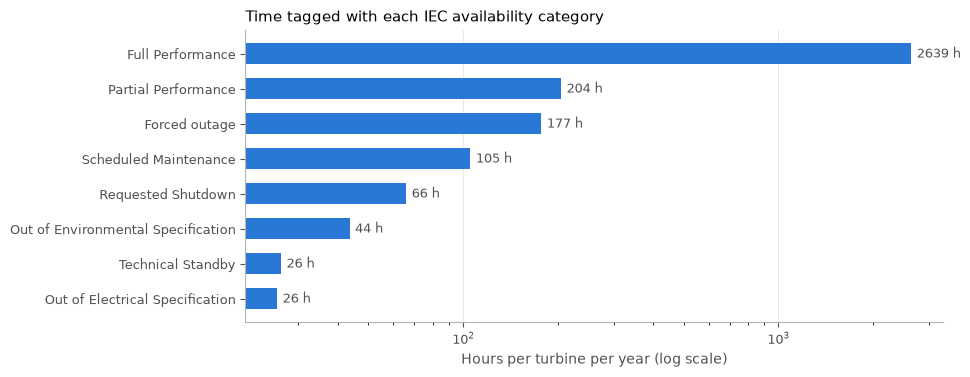

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.8))
plot = iec.drop(index=[i for i in iec.index if pd.isna(i)])["hours_per_turbine_year"].iloc[::-1]
bars = ax.barh(plot.index.astype(str), plot.values, color=PALETTE[0], height=0.6)
ax.bar_label(bars, fmt="%.0f h", padding=4, fontsize=9, color=MUTED)
ax.set_xscale("log")
ax.set_xlabel("Hours per turbine per year (log scale)", color=MUTED)
ax.set_title("Time tagged with each IEC availability category", loc="left", fontsize=11)
style_ax(ax, grid_axis="x")
plt.show()

## Event logs: Stop events

Stop events are the closest thing to fault records: the turbine stopped producing. Not every Stop is a fault, though. Many are environmental (high wind, icing, cable unwinding), grid-side, or deliberate (manual and park-master stops, maintenance). The service contract category separates these, grouped here into six classes.

In [13]:
# service_contract_category -> class; defined in penmanshiel.py so the analysis notebooks use the same classes.
from penmanshiel import STOP_GROUPS

GROUP_OF = {cat: g for g, cats in STOP_GROUPS.items() for cat in cats}
GROUP_COLOR = dict(zip(STOP_GROUPS, PALETTE))

stops = status[status["status"] == "Stop"].copy()
stops["group"] = stops["service_contract_category"].astype(str).map(GROUP_OF).fillna("Other")
stops["hours"] = stops["duration"] / pd.Timedelta("1h")
print(f"{len(stops):,} Stop events, {stops['hours'].sum():,.0f} hours in total")
unmapped = stops.loc[stops["group"] == "Other", "service_contract_category"].value_counts(dropna=False)
if len(unmapped):
    print("Unmapped categories:", unmapped.to_dict())
(stops.groupby("group").agg(events=("code", "size"), hours=("hours", "sum"),
                            median_minutes=("hours", lambda h: 60 * h.median()))
 .sort_values("hours", ascending=False).round(1))

20,021 Stop events, 43,745 hours in total
Unmapped categories: {nan: 1}


,events,hours,median_minutes
group,,,
Turbine fault,3284,14247.0,10.3
Manual / service,2226,10764.9,43.1
Remote / park stop,563,10360.6,316.4
Grid,1602,2938.7,1.0
Environment,4255,2823.0,17.2
Operating state,8090,2610.8,2.3
Other,1,0.0,1.7


### Which codes cost the most downtime

Top Stop codes by total hours across the farm, coloured by class. Long manual and park-master stops dominate total hours. High-wind stops (`Max. wind speed`) and cable unwinding are frequent but short.

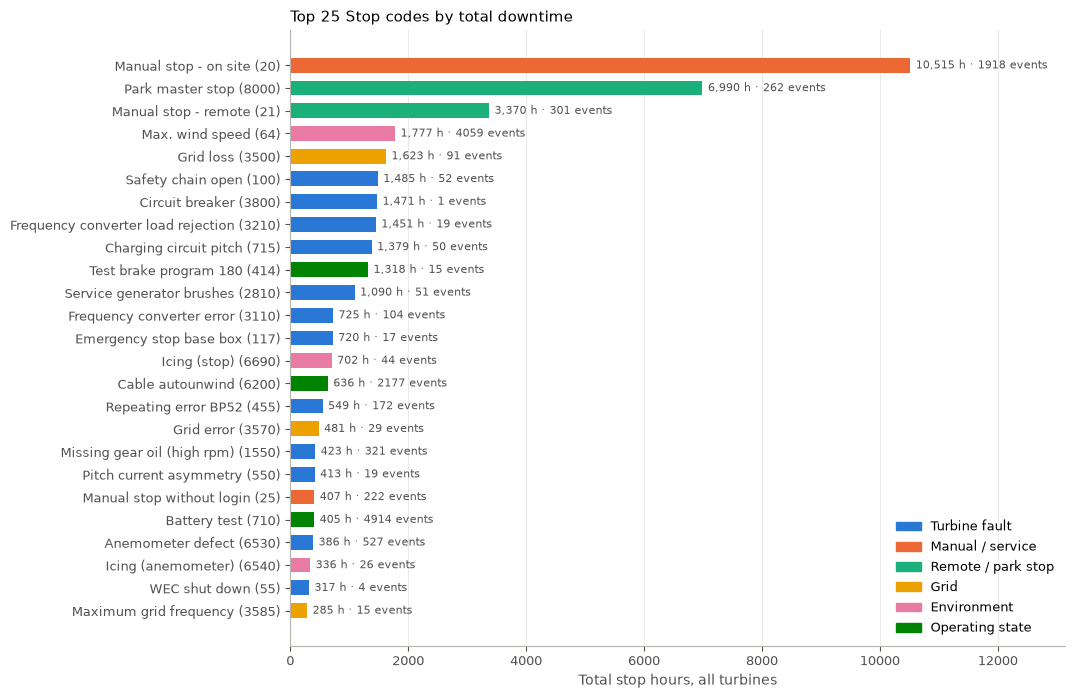

In [14]:
# A few codes appear under more than one contract category; give each code its most common class.
top = (stops.groupby(["code", "message"], observed=True)
       .agg(group=("group", lambda g: g.mode().iloc[0]), events=("code", "size"), hours=("hours", "sum"),
            turbines=("turbine_id", "nunique"))
       .reset_index().sort_values("hours", ascending=False))
top_n = top.head(25).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh([f"{m} ({c})" for c, m in zip(top_n["code"], top_n["message"])], top_n["hours"],
               color=[GROUP_COLOR.get(g, AXIS) for g in top_n["group"]], height=0.65)
ax.bar_label(bars, labels=[f"{h:,.0f} h · {n} events" for h, n in zip(top_n["hours"], top_n["events"])],
             padding=4, fontsize=8, color=MUTED)
ax.set_xlabel("Total stop hours, all turbines", color=MUTED)
ax.set_title("Top 25 Stop codes by total downtime", loc="left", fontsize=11)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLOR.values()],
          labels=list(GROUP_COLOR), loc="lower right", frameon=False, fontsize=9)
ax.set_xlim(0, top_n["hours"].max() * 1.25)
style_ax(ax, grid_axis="x")
plt.show()

In [15]:
# Turbine-fault codes only: the most likely candidates for fault labels.
top[top["group"] == "Turbine fault"].head(30).round(1)

,code,message,group,events,hours,turbines
9,100,Safety chain open,Turbine fault,52,1484.7,12
82,3800,Circuit breaker,Turbine fault,1,1471.2,1
70,3210,Frequency converter load rejection,Turbine fault,19,1450.6,12
42,715,Charging circuit pitch,Turbine fault,50,1379.4,13
65,2810,Service generator brushes,Turbine fault,51,1090.4,7
67,3110,Frequency converter error,Turbine fault,104,724.9,14
11,117,Emergency stop base box,Turbine fault,17,720.3,13
23,455,Repeating error BP52,Turbine fault,172,548.9,14
52,1550,Missing gear oil (high rpm),Turbine fault,321,423.3,14
25,550,Pitch current asymmetry,Turbine fault,19,413.4,7


### Stop timeline per turbine

Each bar is one Stop event, coloured by class. Events shorter than a few hours are barely visible at this scale, so long outages stand out. Vertical stripes across many turbines are farm-wide events (grid outages, park-master stops), such as the remote/park stop across the whole farm in September 2020, which is also the low-coverage stripe in the SCADA coverage plot. The cluster of long stops in June–August 2016 is commissioning, before commercial operation began on 2016-09-01.

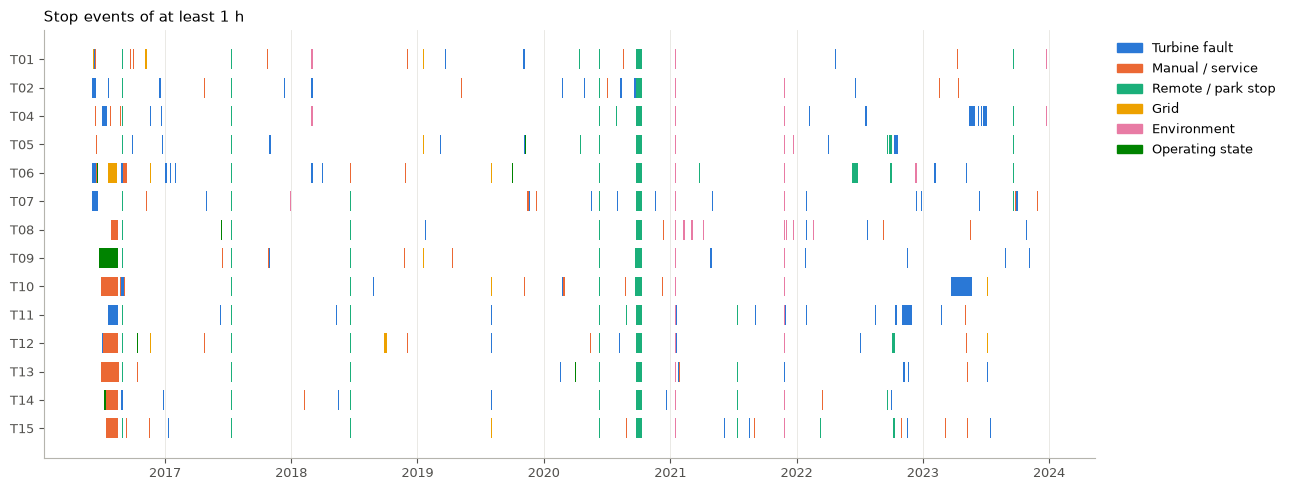

In [16]:
def stop_timeline(stops, groups=None, start=None, end=None, min_hours=0):
    sel = stops if groups is None else stops[stops["group"].isin(groups)]
    sel = sel[sel["hours"] >= min_hours]
    if start is not None:
        sel = sel[sel["timestamp_end"] >= pd.Timestamp(start)]
    if end is not None:
        sel = sel[sel["timestamp_start"] <= pd.Timestamp(end)]
    fig, ax = plt.subplots(figsize=(13, 5))
    for row, t in enumerate(TURBINE_IDS):
        ev = sel[sel["turbine_id"] == t]
        for g, evg in ev.groupby("group"):
            starts = mdates.date2num(evg["timestamp_start"])
            widths = mdates.date2num(evg["timestamp_end"]) - starts
            ax.broken_barh(list(zip(starts, widths)), (row - 0.35, 0.7), color=GROUP_COLOR.get(g, AXIS), lw=0)
    ax.set_yticks(range(len(TURBINE_IDS)), [label(t) for t in TURBINE_IDS])
    ax.invert_yaxis()
    ax.xaxis_date()
    if start is not None or end is not None:
        ax.set_xlim(pd.Timestamp(start) if start else None, pd.Timestamp(end) if end else None)
    shown = [g for g in GROUP_COLOR if g in set(sel["group"])]
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=GROUP_COLOR[g]) for g in shown], labels=shown,
              loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=9)
    ax.set_title(f"Stop events{f' of at least {min_hours} h' if min_hours else ''}", loc="left", fontsize=11)
    style_ax(ax, grid_axis="x")
    fig.tight_layout()
    plt.show()

stop_timeline(stops, min_hours=1)

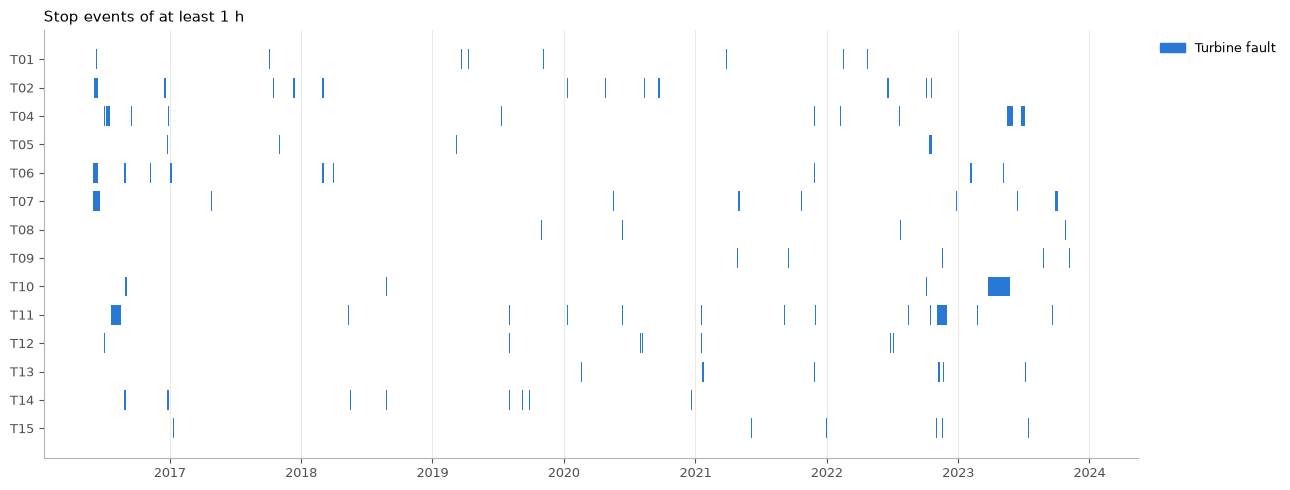

In [17]:
stop_timeline(stops, groups=["Turbine fault"], min_hours=1)

### Monthly turbine-fault downtime

Hours per turbine per month lost to Stop events in the *Turbine fault* class (single-hue scale, darker = more hours, capped at 100 h). This shows where the fault stops cluster, which is where a detector would have something to find.

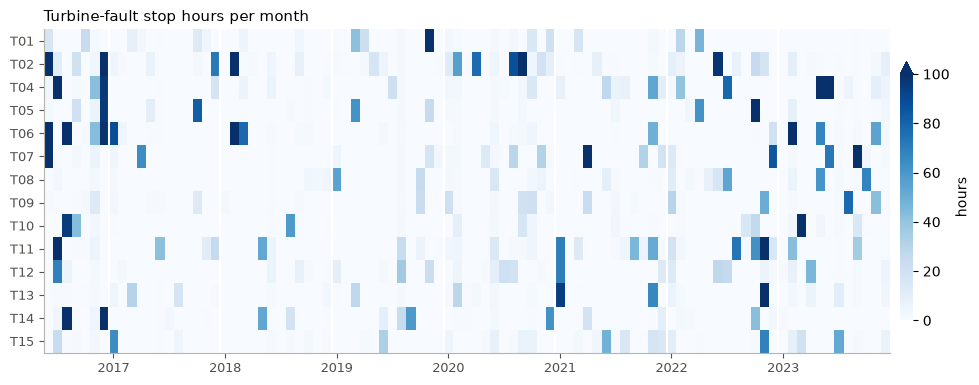

,turbine_id,timestamp_start,timestamp_end,hours,code,message,service_contract_category
679527,10,2023-03-24 01:43:36,2023-05-24 08:55:13,1471.2,3800,Circuit breaker,Electrical error (24)
679526,10,2023-03-24 01:43:36,2023-05-22 11:37:53,1425.9,3210,Frequency converter load rejection,Generator and Converter errors (20)
691333,11,2016-07-20 16:00:37,2016-08-19 12:11:19,716.2,117,Emergency stop base box,Emergency stop switch (Converter) (12)
742740,11,2022-11-02 07:44:29,2022-12-01 15:13:37,703.5,2810,Service generator brushes,Generator and Converter errors (20)
202908,4,2023-05-15 10:40:16,2023-06-01 12:37:46,410.0,20,Manual stop - on site,Generator and Converter errors (20)
371090,7,2016-06-02 17:45:07,2016-06-15 13:29:14,307.7,100,Safety chain open,Safety chain (13)
295449,6,2016-06-02 18:02:26,2016-06-15 11:58:03,305.9,100,Safety chain open,Safety chain (13)
204205,4,2023-06-23 14:08:57,2023-07-05 09:26:45,283.3,55,WEC shut down,WEC Shutdown (1)
64741,2,2016-06-03 08:54:48,2016-06-14 11:42:17,266.8,100,Safety chain open,Safety chain (13)
279204,5,2022-10-11 03:38:06,2022-10-21 14:26:07,250.8,715,Charging circuit pitch,Pitch errors (18)


In [18]:
fault_stops = stops[stops["group"] == "Turbine fault"]
monthly_fault = (fault_stops.groupby(["turbine_id", pd.Grouper(key="timestamp_start", freq="MS")])["hours"].sum()
                 .unstack(fill_value=0).reindex(index=TURBINE_IDS, columns=coverage.columns, fill_value=0))
fig, ax = plt.subplots(figsize=(13, 4.2))
im = ax.imshow(monthly_fault.to_numpy(), aspect="auto", cmap="Blues", vmin=0, vmax=100, interpolation="none")
ax.set_yticks(range(len(TURBINE_IDS)), [label(t) for t in TURBINE_IDS])
ax.set_xticks(year_starts, [months[i].year for i in year_starts])
for i in year_starts:
    ax.axvline(i - 0.5, color="white", lw=1.5)
ax.set_title("Turbine-fault stop hours per month", loc="left", fontsize=11)
cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.01, extend="max", label="hours")
cb.outline.set_visible(False)
style_ax(ax, grid_axis=None)
plt.show()

longest = fault_stops.sort_values("hours", ascending=False).head(15)
longest[["turbine_id", "timestamp_start", "timestamp_end", "hours", "code", "message",
         "service_contract_category"]].round({"hours": 1})

### Operator comments

Free-text comments are rare but explain some long stops (maintenance campaigns, testing, comms loss).

In [19]:
comments = status[status["comment"].notna()]
print(f"{len(comments):,} rows with a comment ({len(comments) / len(status):.2%})")
(comments.groupby("comment", observed=True)
 .agg(rows=("code", "size"), turbines=("turbine_id", lambda s: sorted(s.unique())),
      first=("timestamp_start", "min"), last=("timestamp_start", "max"))
 .sort_values("rows", ascending=False).head(25))

522 rows with a comment (0.05%)


,rows,turbines,first,last
comment,,,,
Turbine HV and Converter Maintenance,98,"[1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]",2022-09-19 07:30:52,2023-09-21 07:20:59
Tower displacement testing,56,"[1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]",2023-02-09 08:37:00,2023-02-10 13:52:03
Ended by code 0,44,"[1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]",2022-11-02 11:19:55,2023-10-02 05:55:51
High Winds,25,"[1, 2, 4, 5, 6, 8, 10, 11, 12, 13, 14, 15]",2023-02-02 21:55:15,2023-02-17 09:42:27
Delayed 2022 annual and 2023 semi-annual service,19,"[1, 8, 9, 11, 12, 13, 14, 15]",2023-05-02 07:31:23,2023-05-15 08:04:47
Gear oil exchange,16,"[1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]",2023-11-01 07:53:25,2023-12-13 12:12:56
BoP HV Maintenance,14,"[1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]",2023-07-11 07:41:52,2023-07-11 07:41:53
Annual HV Maintenance,13,"[1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15]",2022-07-05 07:00:01,2022-07-05 07:00:02
Loss of comms to Greenbyte - SGRE restarted the IEC server.,13,"[1, 2, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15]",2022-11-25 15:45:46,2022-11-25 15:46:06


### A fault stop in the SCADA data

The longest turbine-fault stop, with that turbine's power and wind speed for two weeks either side. The shaded span is the stop. This checks that the status log and the SCADA agree: power should drop to zero while wind continues.

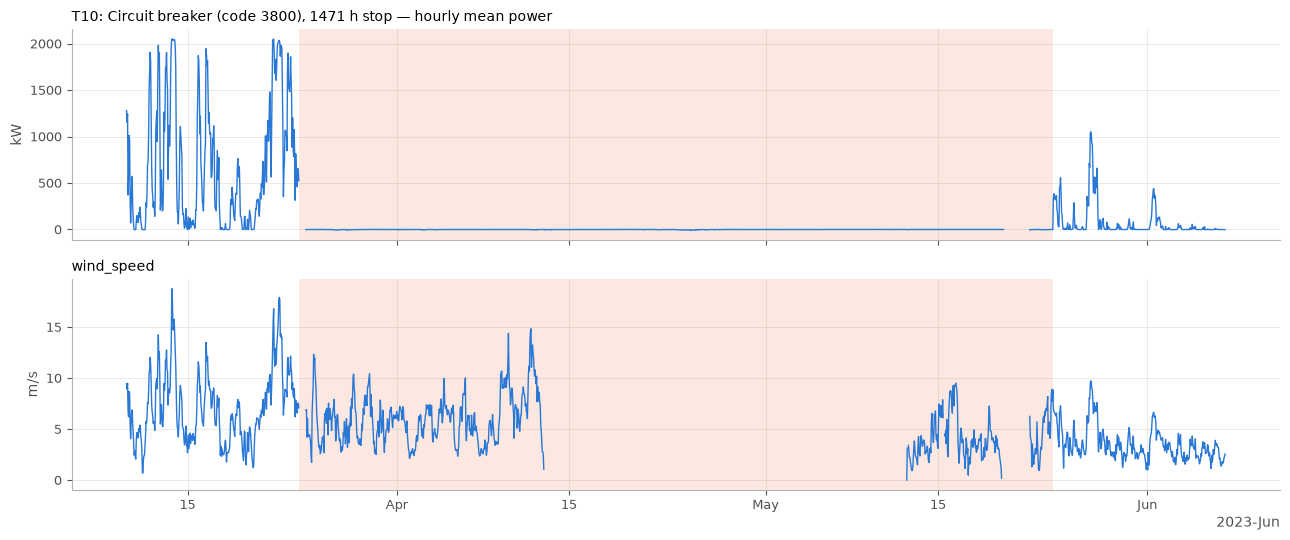

In [20]:
ev = longest.iloc[0]
t = int(ev["turbine_id"])
lo, hi = ev["timestamp_start"] - pd.Timedelta(days=14), ev["timestamp_end"] + pd.Timedelta(days=14)
d = pd.read_parquet(DATA / "scada" / f"{t}.parquet", columns=["time_stamp", "power", "wind_speed"],
                    filters=[("time_stamp", ">=", lo), ("time_stamp", "<=", hi)]).set_index("time_stamp")
d = d.resample("1h").mean()

fig, axes = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
for ax, col, unit in zip(axes, ["power", "wind_speed"], ["kW", "m/s"]):
    ax.plot(d.index, d[col], color=PALETTE[0], lw=1)
    ax.axvspan(ev["timestamp_start"], ev["timestamp_end"], color=PALETTE[1], alpha=0.15, lw=0)
    ax.set_ylabel(unit, color=MUTED)
    ax.set_title(col, loc="left", fontsize=10)
    style_ax(ax)
axes[0].set_title(f"{label(t)}: {ev['message']} (code {ev['code']}), {ev['hours']:.0f} h stop — hourly mean power",
                  loc="left", fontsize=10)
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(axes[1].xaxis.get_major_locator()))
fig.tight_layout()
plt.show()

### Forced outages by duration

Every status row in the IEC *Forced outage* category (unplanned stops caused by the turbine) that has a duration, longest first. Most are Stops; a few are Warnings that the log also puts in this category. Rows on the same turbine can overlap, for example a stop and a warning raised by the same fault, so the hours below are time *tagged* as a forced outage rather than a sum of separate events. The table scrolls.

In [21]:
from IPython.display import HTML

fo = (status[(status["iec_category"] == "Forced outage") & status["duration"].notna()]
      .sort_values("duration", ascending=False).reset_index(drop=True))
fo_hours = fo["duration"] / pd.Timedelta("1h")
q = fo_hours.quantile([0.5, 0.9, 0.99])
top_share = lambda n: fo_hours.iloc[:n].sum() / fo_hours.sum()
print(f"{len(fo):,} forced-outage rows ({(fo['status'] == 'Stop').mean():.0%} Stops), {fo_hours.sum():,.0f} h tagged in total")
print(f"Duration: median {q[0.5] * 60:.1f} min, 90th percentile {q[0.9]:.1f} h, 99th percentile {q[0.99]:.0f} h; "
      f"{(fo_hours < 1).mean():.0%} last under an hour")
print(f"The longest 10 rows hold {top_share(10):.0%} of the hours, the longest 100 hold {top_share(100):.0%}")


def fmt_duration(d):
    s = int(d.total_seconds())
    days, s = divmod(s, 86400)
    h, s = divmod(s, 3600)
    m, s = divmod(s, 60)
    return f"{days} d {h:02d}:{m:02d}" if days else (f"{h} h {m:02d} min" if h else f"{m} min {s:02d} s")


fo_table = pd.DataFrame({
    "rank": range(1, len(fo) + 1),
    "turbine": fo["turbine_id"].map(label),
    "start": fo["timestamp_start"].dt.strftime("%Y-%m-%d %H:%M"),
    "end": fo["timestamp_end"].dt.strftime("%Y-%m-%d %H:%M"),
    "duration": fo["duration"].map(fmt_duration),
    "hours": fo_hours.round(2),
    "status": fo["status"].astype(str),
    "code": fo["code"],
    "message": fo["message"],
    "category": fo["service_contract_category"].astype(str).str.replace(r"\s*\(\d+\)$", "", regex=True),
    "comment": fo["comment"].astype(object).fillna(""),
})
display(HTML('<div style="max-height: 520px; overflow: auto; font-size: 12px">'
             + fo_table.to_html(index=False, escape=True) + "</div>"))

5,644 forced-outage rows (86% Stops), 18,767 h tagged in total
Duration: median 5.8 min, 90th percentile 3.1 h, 99th percentile 64 h; 81% last under an hour
The longest 10 rows hold 33% of the hours, the longest 100 hold 68%


rank,turbine,start,end,duration,hours,status,code,message,category,comment
1,T10,2023-03-24 01:43,2023-05-24 08:55,61 d 07:11,1471.19,Stop,3800,Circuit breaker,Electrical error,Bus bar replacement and errors following the replacement. Software updated on 26/5/23
2,T10,2023-03-24 01:43,2023-05-22 11:37,59 d 09:54,1425.90,Stop,3210,Frequency converter load rejection,Generator and Converter errors,Tower Bus Bar Blown - Waiting for parts and rope access team. Last update from SGRE is that there is a delay on parts of a few weeks
3,T11,2016-07-20 16:00,2016-08-19 12:11,29 d 20:10,716.18,Stop,117,Emergency stop base box,Emergency stop switch (Converter),
4,T11,2022-11-02 07:44,2022-12-01 15:13,29 d 07:29,703.49,Stop,2810,Service generator brushes,Generator and Converter errors,Sun pinion retrofit - and failed Bachman processor. Pitch motor replacement. Various issues with Bachman processor
5,T06,2022-06-09 17:20,2022-06-28 16:12,18 d 22:52,454.87,Stop,21,Manual stop - remote,Remote stop,Pitch fault SWO not lifted due to requirement to do further trials
6,T07,2016-06-02 17:45,2016-06-15 13:29,12 d 19:44,307.74,Stop,100,Safety chain open,Safety chain,
7,T06,2016-06-02 18:02,2016-06-15 11:58,12 d 17:55,305.93,Stop,100,Safety chain open,Safety chain,
8,T04,2023-06-23 14:08,2023-07-05 09:26,11 d 19:17,283.30,Stop,55,WEC shut down,WEC Shutdown,Converter fault - could be encoder or encoder shaft
9,T02,2016-06-03 08:54,2016-06-14 11:42,11 d 02:47,266.79,Stop,100,Safety chain open,Safety chain,
10,T05,2022-10-11 03:38,2022-10-21 14:26,10 d 10:48,250.80,Stop,715,Charging circuit pitch,Pitch errors,Pitch motor replacement - delays in getting the parts and also affected by OR on hoists


## Fault labels: what the analysis uses and how far to trust them

The analysis notebooks (`population_form_penmanshiel.ipynb` benchmark, `analysis_penmanshiel.ipynb` validation) take as fault labels every **Stop** row in the *Turbine fault* class (`pm.TURBINE_FAULT_CATEGORIES`, 14 service-contract categories), from commercial operation onwards. Each row is a controller stop code with a start and end time. The log does not say whether a component was actually defective; it says that a protection or check stopped the turbine.

This section collects evidence, code by code, on whether these labels mark real component faults:

| Evidence | What it tells you |
|---|---|
| **episodes, busiest turbine** | Repeats of one code on one turbine less than a day apart count as one episode. Many stops in few episodes, or most of them on one turbine, point to one persistent problem rather than many faults. |
| **< 10 min, ≥ 1 h** | Stops that clear within minutes are usually automatic resets after a transient. Stops of an hour or more usually needed a person, remotely or on site. |
| **farm-wide** | Share of stops where at least 3 other turbines also stopped within ±10 min. A component fault is specific to one turbine; simultaneous stops point to the grid, the weather or a park-level command. |
| **service within 7 d** | Share followed by a *Manual / service* stop on the same turbine within 7 days: a sign that someone went to fix it. Compare it with the baseline printed below it (the same rate from a random time). |
| **comment** | Share of rows with an operator comment. |
| **wind before, ambient temp** | SCADA in the 10 minutes before the stop. Very high wind points to storm protection; low wind to start-up or measurement checks. |
| **running before** | Share where the turbine was producing (> 20 kW) just before. A stop that only happens at standstill is a start-up check, not a fault in operation. |
| **SCADA shows stopped** | For stops of 30 min or more, the share of 10-minute slots inside the logged stop with power < 20 kW. Near 100% means the log and SCADA timestamps agree; a low value means the logged times are wrong. |

In [22]:
# Evidence per turbine-fault Stop row (from commercial operation): repeats, duration, farm-wide coincidence,
# service follow-up, operator comments and the SCADA conditions around the stop.
import penmanshiel as pm

FARM_WINDOW = pd.Timedelta(minutes=10)   # stops on other turbines starting this close count as simultaneous
FARM_MIN_OTHERS = 3                      # ... and at least this many other turbines make a stop farm-wide
SERVICE_DAYS = 7                         # manual/service stop on the same turbine within this many days after
EPISODE_GAP = pd.Timedelta(days=1)       # repeats of one code on one turbine closer than this are one episode

after_cod = stops[stops["timestamp_start"] >= pm.COMMERCIAL_OPERATION]
fs = after_cod[after_cod["group"] == "Turbine fault"].copy().reset_index(drop=True)
fs["category"] = fs["service_contract_category"].str.replace(r"\s*\(\d+\)\s*$", "", regex=True).str.split().str.join(" ")
fs["minutes"] = fs["hours"] * 60

# Farm-wide: other turbines with a Stop (any class) starting within FARM_WINDOW.
_all = after_cod.sort_values("timestamp_start")
_ts, _tid = _all["timestamp_start"].to_numpy(), _all["turbine_id"].to_numpy()
_lo = np.searchsorted(_ts, (fs["timestamp_start"] - FARM_WINDOW).to_numpy())
_hi = np.searchsorted(_ts, (fs["timestamp_start"] + FARM_WINDOW).to_numpy(), "right")
fs["other_turbines"] = [len(set(_tid[a:b]) - {t}) for a, b, t in zip(_lo, _hi, fs["turbine_id"])]


# Service follow-up, with a baseline: the same test from noon on every day of operation.
_svc = {t: np.sort(g["timestamp_start"].to_numpy()) for t, g in after_cod[after_cod["group"] == "Manual / service"].groupby("turbine_id")}
def _service_after(turbine, times):
    s = _svc.get(turbine)
    if s is None:
        return np.zeros(len(times), bool)
    # a service stop starts in [t, t + SERVICE_DAYS]
    return np.searchsorted(s, times + np.timedelta64(SERVICE_DAYS, "D"), "right") > np.searchsorted(s, times)
fs["service_after"] = False
for t, idx in fs.groupby("turbine_id").groups.items():
    fs.loc[idx, "service_after"] = _service_after(t, fs.loc[idx, "timestamp_start"].to_numpy())
_days = pd.date_range(pm.COMMERCIAL_OPERATION, status["timestamp_start"].max(), freq="D") + pd.Timedelta(hours=12)
service_baseline = np.mean([_service_after(t, _days.to_numpy()).mean() for t in TURBINE_IDS])

# Episodes: runs of the same code on one turbine.
fs = fs.sort_values(["turbine_id", "code", "timestamp_start"])
_new = fs.groupby(["turbine_id", "code"])["timestamp_start"].diff().gt(EPISODE_GAP) | fs.groupby(["turbine_id", "code"]).cumcount().eq(0)
fs["episode"] = _new.cumsum()
fs = fs.sort_values(["turbine_id", "timestamp_start"]).reset_index(drop=True)

# SCADA around the stop: conditions in the slot before it, and whether power was ~0 while it was logged.
_sc = pm.load_scada(TURBINE_IDS, ["wind_speed", "power", "nacelle_ambient_temperature"])
fs[["wind_before", "power_before", "temp_before", "scada_stopped"]] = np.nan
for t, idx in fs.groupby("turbine_id").groups.items():
    d = _sc[_sc["turbine_id"] == t]
    times, power = d["time_stamp"].to_numpy(), d["power"].to_numpy()
    g = fs.loc[idx]
    j = np.searchsorted(times, (g["timestamp_start"].dt.floor("10min") - pd.Timedelta("10min")).to_numpy())
    hit = (j < len(times)) & (times[np.minimum(j, len(times) - 1)] == (g["timestamp_start"].dt.floor("10min") - pd.Timedelta("10min")).to_numpy())
    jj = np.minimum(j, len(times) - 1)
    for col, src in [("wind_before", "wind_speed"), ("power_before", "power"), ("temp_before", "nacelle_ambient_temperature")]:
        fs.loc[idx, col] = np.where(hit, d[src].to_numpy()[jj], np.nan)
    # slots fully inside the stop: [ceil(start), floor(end) - 10 min]; only stops of 30 min or more
    valid = np.isfinite(power)
    c_stop, c_valid = np.r_[0, np.cumsum(valid & (power < 20))], np.r_[0, np.cumsum(valid)]
    a = np.searchsorted(times, g["timestamp_start"].dt.ceil("10min").to_numpy())
    b = np.searchsorted(times, (g["timestamp_end"].dt.floor("10min") - pd.Timedelta("10min")).to_numpy(), "right")
    n = c_valid[b] - c_valid[np.minimum(a, b)]
    share = np.where(n > 0, (c_stop[b] - c_stop[np.minimum(a, b)]) / np.maximum(n, 1), np.nan)
    fs.loc[idx, "scada_stopped"] = np.where(g["minutes"].to_numpy() >= 30, share, np.nan)


def evidence(g):
    """Evidence columns for a group of fault stops."""
    top = g["turbine_id"].value_counts()
    return pd.Series({
        "stops": len(g), "turbines": g["turbine_id"].nunique(), "episodes": g["episode"].nunique(),
        "busiest turbine": f"{label(top.index[0])} ({top.iloc[0] / len(g):.0%})",
        "median minutes": g["minutes"].median(), "< 10 min": (g["minutes"] < 10).mean(),
        "≥ 1 h": (g["minutes"] >= 60).mean(), "farm-wide": (g["other_turbines"] >= FARM_MIN_OTHERS).mean(),
        "service within 7 d": g["service_after"].mean(), "comment": g["comment"].notna().mean(),
        "wind before (m/s)": g["wind_before"].median(), "ambient temp (°C)": g["temp_before"].median(),
        "running before": (g["power_before"] > 20).mean(), "SCADA shows stopped": g["scada_stopped"].mean()})


EVIDENCE_FMT = {c: "{:.0%}" for c in ["< 10 min", "≥ 1 h", "farm-wide", "service within 7 d", "comment",
                                       "running before", "SCADA shows stopped"]} | {
    "median minutes": "{:.0f}", "wind before (m/s)": "{:.1f}", "ambient temp (°C)": "{:.1f}"}
by_cat = fs.groupby("category").apply(evidence, include_groups=False).sort_values("stops", ascending=False)
print(f"{len(fs):,} turbine-fault Stop rows since {pm.COMMERCIAL_OPERATION:%Y-%m-%d}, {fs['code'].nunique()} codes, "
      f"{fs['category'].nunique()} categories")
print(f"Baseline for 'service within {SERVICE_DAYS} d': {service_baseline:.0%} of random turbine-days are followed by a "
      f"service stop that soon. Median wind over all SCADA: {_sc['wind_speed'].median():.1f} m/s.")
display(by_cat.style.format(EVIDENCE_FMT, na_rep="–"))

3,155 turbine-fault Stop rows since 2016-09-01, 65 codes, 14 categories
Baseline for 'service within 7 d': 20% of random turbine-days are followed by a service stop that soon. Median wind over all SCADA: 6.3 m/s.


,stops,turbines,episodes,busiest turbine,median minutes,< 10 min,≥ 1 h,farm-wide,service within 7 d,comment,wind before (m/s),ambient temp (°C),running before,SCADA shows stopped
category,,,,,,,,,,,,,,
Generator and Converter errors,784,14,262,T11 (14%),2,64%,16%,48%,28%,3%,7.4,11.5,15%,100%
Safety stop of WEC,772,14,527,T02 (20%),14,5%,9%,71%,19%,2%,20.5,9.9,25%,98%
Sensor error,592,14,159,T12 (28%),2,83%,6%,1%,43%,1%,3.6,10.2,41%,97%
Mechanical error,400,14,227,T11 (20%),2,64%,14%,15%,42%,3%,9.1,8.8,60%,100%
Pitch errors,241,14,145,T02 (15%),23,16%,39%,8%,54%,9%,5.0,9.8,38%,100%
Repeated error,160,14,107,T09 (13%),19,29%,26%,40%,49%,2%,6.6,8.6,34%,95%
Electrical error,145,13,46,T10 (28%),2,65%,22%,2%,30%,6%,6.5,13.3,10%,100%
Safety chain,32,12,26,T02 (34%),27,12%,34%,0%,50%,0%,4.8,10.6,38%,100%
Controller error of the WP3100,17,8,14,T14 (24%),10,0%,6%,24%,12%,0%,4.3,10.2,65%,100%


### Code-by-code review

Each code with at least 3 stops gets a **label type** and a **confidence**: how likely a stop with this code marks a genuine component problem, the kind that could build up in the SCADA data beforehand. Both are judgements from the evidence above and the code's message, kept in `LABEL_REVIEW` so they can be changed. Codes with fewer than 3 stops are *Not reviewed*.

| Label type | Meaning |
|---|---|
| **Component fault** | A protection that tripped on a measured component problem (converter, pitch drive or battery, gearbox oil, brake) |
| **Sensor / measurement** | The measuring device failed or disagreed, not the drivetrain. It is real, but only visible in the signals that use that sensor. |
| **Storm or weather protection** | A protective stop in high wind or oscillation: the turbine did its job |
| **Start-up / grid** | Raised while the turbine was not producing, or together with other turbines: start-up checks and grid connection |
| **Maintenance or manual** | Planned work or people on site, filed under a fault category |
| **Unclear** | Meta-codes or mixed evidence |

In [23]:
# Label type and confidence per stop code (judgement from the evidence table and the message; edit freely).
LABEL_TYPES = ["Component fault", "Sensor / measurement", "Storm or weather protection", "Start-up / grid",
               "Maintenance or manual", "Unclear", "Not reviewed"]
TYPE_COLOR = dict(zip(LABEL_TYPES, PALETTE[:5] + [PALETTE[6], "#cfcec8"]))
CONFIDENCE = ["High", "Medium", "Low", "Not reviewed"]
LABEL_REVIEW = {  # code: (label type, confidence, reason)
    3000: ("Start-up / grid", "Low", "82% clear in < 10 min, 62% farm-wide, never raised while producing"),
    6530: ("Sensor / measurement", "Medium", "real anemometer faults (T08, T02, T12; only from 2021), but mostly 2-min trips at low wind"),
    4510: ("Storm or weather protection", "Low", "median wind 21 m/s, 69% farm-wide"),
    4530: ("Storm or weather protection", "Low", "median wind 21 m/s, 83% farm-wide"),
    4520: ("Storm or weather protection", "Low", "median wind 17 m/s, 49% farm-wide"),
    4540: ("Storm or weather protection", "Low", "median wind 20 m/s, 75% farm-wide"),
    1550: ("Unclear", "Low", "74% clear in < 10 min while running; transient oil-level trip at high rpm"),
    455: ("Unclear", "Low", "meta-code for a repeating error: says nothing about the component; 40% farm-wide, 60% in 2016"),
    3125: ("Start-up / grid", "Low", "never raised while producing; grid connection at start-up"),
    3110: ("Component fault", "High", "converter fault: median 21 min, 33% over 1 h, 49% followed by service; 48% on T08"),
    650: ("Component fault", "Medium", "pitch communication loss; mostly at standstill, 53% followed by service"),
    1510: ("Component fault", "Medium", "69% on T04 (a persistent problem), but 37% farm-wide (cold starts after outages?)"),
    715: ("Component fault", "High", "pitch charging circuit: median 3.5 h, 18% commented"),
    2810: ("Maintenance or manual", "Low", "scheduled generator brush service (76% on T11)"),
    100: ("Unclear", "Medium", "safety chain opens on real faults and during on-site work alike"),
    3555: ("Component fault", "High", "all 31 on T04 in 8 episodes: one persistent electrical problem"),
    6620: ("Sensor / measurement", "Medium", "wind vane; short trips at low wind"),
    1620: ("Sensor / measurement", "Medium", "speed sensor disagreement, half on T02"),
    6120: ("Component fault", "Medium", "yaw brake or drive; short trips while running"),
    550: ("Component fault", "High", "pitch current asymmetry: median 3.6 h, 79% followed by service, 42% commented"),
    820: ("Storm or weather protection", "Low", "all < 10 min, 89% farm-wide: rotor turned backwards in light wind"),
    2100: ("Component fault", "High", "brake feedback, all on T15 in 13 episodes"),
    582: ("Component fault", "Medium", "pitch axis 2 not following its set point"),
    581: ("Component fault", "Medium", "pitch axis 1 not following its set point"),
    692: ("Component fault", "Medium", "pitch run-away"),
    1800: ("Component fault", "Medium", "gear oil pump overload"),
    3210: ("Start-up / grid", "Low", "converter load rejection, 60% farm-wide: grid event"),
    665: ("Component fault", "Medium", "generic pitch error, mostly short"),
    60: ("Storm or weather protection", "Low", "power above what the wind supports: measurement or gusts"),
    4215: ("Unclear", "Low", "smoke warning: long stops, probably detector faults or inspections"),
    700: ("Component fault", "Medium", "pitch battery voltage"),
    1924: ("Component fault", "High", "gear oil particle count: wear debris"),
    735: ("Component fault", "Medium", "pitch battery voltage, axis 3"),
    3650: ("Component fault", "Medium", "one T15 episode"),
    3750: ("Start-up / grid", "Low", "grid measurement"),
    658: ("Component fault", "High", "pitch converter: median 18 h, 80% followed by service"),
    725: ("Component fault", "Medium", "pitch battery voltage, axis 1"),
    7335: ("Maintenance or manual", "Low", "configuration check, 75% farm-wide: software update"),
    4225: ("Unclear", "Low", "smoke warning at the tower base"),
    657: ("Component fault", "High", "pitch converter: median 17 h, 75% followed by service"),
    570: ("Component fault", "High", "pitch too slow: all over 1 h"),
    555: ("Component fault", "Medium", "pitch angle deviation"),
    55: ("Maintenance or manual", "Low", "deliberate shut-down"),
    6300: ("Sensor / measurement", "Medium", "yaw misalignment check"),
    1815: ("Component fault", "High", "gear oil cooler fan: all over 1 h, all followed by service"),
    3805: ("Component fault", "Medium", "transformer over-temperature, one turbine"),
}
_rev = pd.DataFrame.from_dict(LABEL_REVIEW, orient="index", columns=["label type", "confidence", "reason"])
fs = fs.drop(columns=["label type", "confidence"], errors="ignore").join(_rev[["label type", "confidence"]], on="code")
fs[["label type", "confidence"]] = fs[["label type", "confidence"]].fillna("Not reviewed")

by_code = fs.groupby(["category", "code", "message"]).apply(evidence, include_groups=False)
by_code = by_code[by_code["stops"] >= 3].join(_rev, on="code").sort_values("stops", ascending=False)
_conf_style = {"High": "background-color: #cde2fb", "Medium": "", "Low": "color: #9a9993"}
display(by_code[["label type", "confidence", "reason"] + list(by_cat.columns)].style
        .format(EVIDENCE_FMT, na_rep="–").map(lambda v: _conf_style.get(v, ""), subset=["confidence"]))

,,,label type,confidence,reason,stops,turbines,episodes,busiest turbine,median minutes,< 10 min,≥ 1 h,farm-wide,service within 7 d,comment,wind before (m/s),ambient temp (°C),running before,SCADA shows stopped
category,code,message,,,,,,,,,,,,,,,,,
Generator and Converter errors,3000,Frequency converter not ready,Start-up / grid,Low,"82% clear in < 10 min, 62% farm-wide, never raised while producing",591,14,159,T09 (11%),2,82%,9%,62%,24%,0%,7.7,11.8,0%,100%
Sensor error,6530,Anemometer defect,Sensor / measurement,Medium,"real anemometer faults (T08, T02, T12; only from 2021), but mostly 2-min trips at low wind",527,14,107,T12 (31%),2,87%,4%,0%,44%,1%,3.7,10.1,44%,95%
Safety stop of WEC,4510,Tower oscillation Y level 1,Storm or weather protection,Low,"median wind 21 m/s, 69% farm-wide",412,14,249,T02 (25%),11,1%,5%,69%,19%,2%,20.6,9.6,28%,100%
Mechanical error,1550,Missing gear oil (high rpm),Unclear,Low,74% clear in < 10 min while running; transient oil-level trip at high rpm,305,14,148,T11 (25%),2,74%,12%,12%,46%,3%,9.1,8.8,68%,100%
Safety stop of WEC,4530,Tower oscillation Y level 2,Storm or weather protection,Low,"median wind 21 m/s, 83% farm-wide",225,14,150,T12 (17%),16,7%,12%,83%,17%,3%,21.0,10.3,11%,100%
Repeated error,455,Repeating error BP52,Unclear,Low,"meta-code for a repeating error: says nothing about the component; 40% farm-wide, 60% in 2016",160,14,107,T09 (13%),19,29%,26%,40%,49%,2%,6.6,8.6,34%,95%
Electrical error,3125,Timeout ready for connection,Start-up / grid,Low,never raised while producing; grid connection at start-up,116,7,24,T10 (33%),2,76%,10%,3%,25%,3%,6.3,13.8,0%,100%
Generator and Converter errors,3110,Frequency converter error,Component fault,High,"converter fault: median 21 min, 33% over 1 h, 49% followed by service; 48% on T08",101,14,56,T08 (48%),21,7%,33%,5%,49%,5%,4.8,8.9,38%,100%
Pitch errors,650,Pitch controller communication error,Component fault,Medium,"pitch communication loss; mostly at standstill, 53% followed by service",98,13,40,T04 (13%),10,18%,18%,16%,53%,2%,4.4,8.5,5%,100%


1,136 events (benchmark merging); best evidence: High 123 (11%), Medium 318 (28%), Low 683 (60%), Not reviewed 12 (1%)


confidence,High,Medium,Low,Not reviewed,events,share High
category,,,,,,
Safety stop of WEC,1,7,375,0,383,0%
Generator and Converter errors,54,1,136,0,191,28%
Sensor error,0,138,0,2,140,0%
Mechanical error,15,52,67,1,135,11%
Pitch errors,47,68,1,4,120,39%
Repeated error,1,7,73,0,81,1%
Electrical error,2,12,25,2,41,5%
Safety chain,1,23,0,0,24,4%
Controller error of the WP3100,0,10,4,0,14,0%


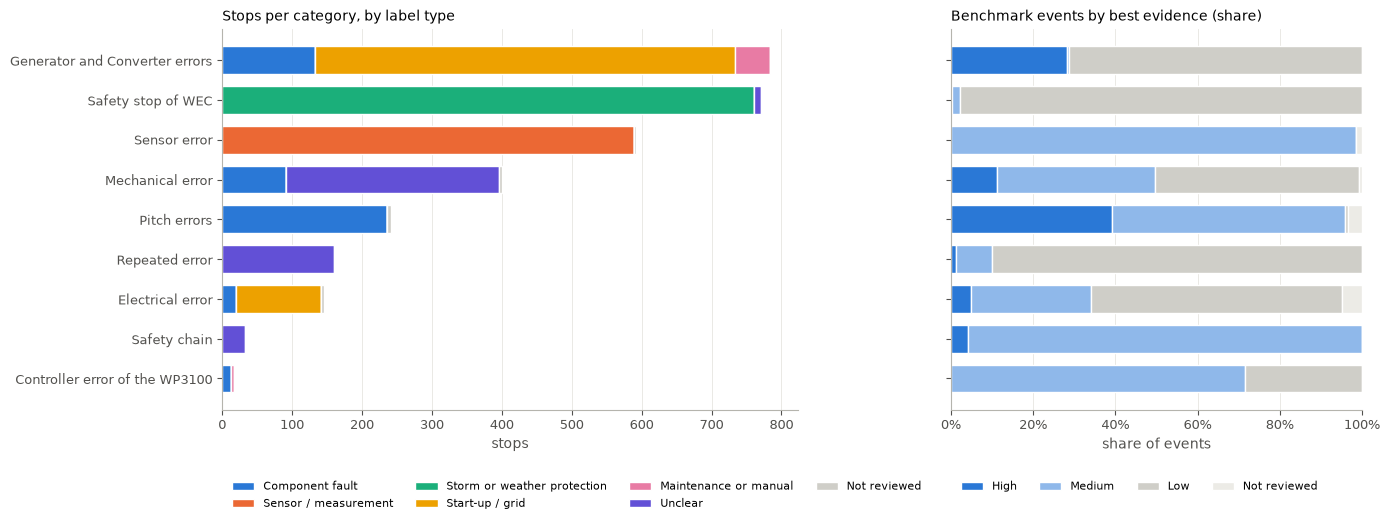

In [24]:
# What the labels are made of: stops per category by label type, and benchmark events by their best evidence.
# Events are built as in the population-form benchmark: fault stops on one turbine less than 24 h apart are one
# event, which takes the category of its longest stop. An event's confidence is the best of its stops'.
_rank = {c: i for i, c in enumerate(CONFIDENCE)}
_e = []
for t, g in fs[fs["timestamp_end"].notna()].sort_values("timestamp_start").groupby("turbine_id"):
    end, cur = None, None
    for r in g.itertuples(index=False):
        if cur is not None and r.timestamp_start <= end + pd.Timedelta(hours=24):
            end = max(end, r.timestamp_end)
            cur["best"] = min(cur["best"], _rank[r.confidence])
            if r.minutes > cur["longest"]:
                cur.update(longest=r.minutes, category=r.category)
        else:
            if cur is not None:
                _e.append(cur)
            end, cur = r.timestamp_end, dict(turbine=t, start=r.timestamp_start, category=r.category,
                                              longest=r.minutes, best=_rank[r.confidence])
    _e.append(cur)
label_events = pd.DataFrame(_e)
label_events["confidence"] = label_events["best"].map(dict(enumerate(CONFIDENCE)))
ev_conf = pd.crosstab(label_events["category"], label_events["confidence"]).reindex(columns=CONFIDENCE, fill_value=0)
ev_conf = ev_conf.loc[ev_conf.sum(axis=1).sort_values(ascending=False).index]
print(f"{len(label_events):,} events (benchmark merging); best evidence: "
      + ", ".join(f"{c} {n:,} ({n / len(label_events):.0%})" for c, n in ev_conf.sum().items()))
display(ev_conf.assign(events=ev_conf.sum(axis=1), **{"share High": ev_conf["High"] / ev_conf.sum(axis=1)})
        .style.format({"share High": "{:.0%}"}))

stop_types = pd.crosstab(fs["category"], fs["label type"]).reindex(columns=LABEL_TYPES, fill_value=0)
stop_types = stop_types.loc[stop_types.sum(axis=1).sort_values().index]
stop_types = stop_types[stop_types.sum(axis=1) >= 10]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), sharey=True, gridspec_kw={"width_ratios": [1.4, 1]})
for ax, data, title, colors in [
        (axes[0], stop_types, "Stops per category, by label type", [TYPE_COLOR[c] for c in LABEL_TYPES]),
        (axes[1], ev_conf.reindex(stop_types.index).div(ev_conf.reindex(stop_types.index).sum(axis=1), axis=0),
         "Benchmark events by best evidence (share)", [PALETTE[0], "#8fb8ea", "#cfcec8", "#ecebe6"])]:
    left = np.zeros(len(data))
    for col, colr in zip(data.columns, colors):
        v = data[col].to_numpy(float)
        ax.barh(range(len(data)), v, left=left, color=colr, height=0.7, label=col, edgecolor="white", linewidth=1)
        left += v
    ax.set_title(title, loc="left", fontsize=10)
    ax.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(0, -0.16), ncol=4 if ax is axes[0] else 4)
    style_ax(ax, grid_axis="x")
axes[0].set_yticks(range(len(stop_types)), stop_types.index, fontsize=9)
axes[0].set_xlabel("stops", color=MUTED)
axes[1].set_xlabel("share of events", color=MUTED)
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout()
plt.show()

### What this says about the fault labels

- **Most labels are not component faults.** Of the 1,136 benchmark events, only 123 (11%) contain a stop with high-confidence component evidence, and another 318 (28%) have medium evidence. The other 60% rest only on low-confidence codes.
- **Three codes dominate the Turbine fault class, and none of them is a fault:**
  - *Frequency converter not ready* (591 stops): never raised while producing, 82% clear within 10 minutes, 62% farm-wide. It is a start-up check after another stop.
  - *Tower oscillation*, levels 1 and 2 in X and Y (734 stops): median wind 17–21 m/s, mostly farm-wide. It is storm protection.
  - *Repeating error BP52* (160 stops): a meta-code that names no component, 60% of them in 2016.

  As a result, *Safety stop of WEC*, *Repeated error* and most of *Generator and Converter errors* are mainly noise as fault labels.
- **The timestamps can be trusted.** SCADA shows power below 20 kW for 95–100% of the logged duration of long stops in every major category, so the log and SCADA are aligned. The question is what a stop means, not when it happened.
- **Where the labels are stronger:**
  - *Pitch errors* (charging circuit, pitch converters, current asymmetry): long, often commented, and followed by service work.
  - *Frequency converter error* (code 3110).
  - Persistent single-turbine problems: *Current asymmetry* on T04, *Feedback brake 1* on T15, *Low gearbox oil pressure* on T04.
  - A service stop follows within 7 days in 50–80% of these, against a baseline of 20%.
- **Sensor errors are real but specific.** *Anemometer defect* appears only from 2021, in episodes on T12, T08 and T02. These are real defects, but only visible in curves that use wind speed. That explains why sensor errors were the most detectable category in the benchmark.
- **The benchmark results make sense in this light.** Detection is weak overall because most events are start-up, storm or meta-code stops with nothing to detect. A cleaner label set would keep only high and medium confidence codes and drop the dominant noise codes.

### A simple vote-based confidence score

Each fault stop gets three equal votes from the evidence above:

| Vote | Condition | Score |
|---|---|---|
| farm-wide | at least 3 other turbines stopped within ±10 min | −1 |
| service | a *Manual / service* stop on the same turbine within 7 days | +1 |
| comment | the row has an operator comment | +1 |

The score runs from −1 to +2 and maps to a level:
- **1 Low** (score −1): farm-wide, with nothing in its favour.
- **2 Medium** (score 0): no evidence either way, or one vote for and one against.
- **3 High** (score +1 or more): followed by service or commented, and on balance not farm-wide.

An **event** (fault stops on one turbine merged with a 24 h gap, as in the benchmark) takes the level of its best stop. Removing low-confidence stops and re-merging shows how much of the label set they account for.

Keep in mind:
- **The service vote is noisy.** 20% of random turbine-days are followed by a service stop anyway, so about 1 in 5 noise stops gets a +1.
- **Comments are rare** (2–3% of stops).
- So in practice, **High mostly means "a service visit followed"** and **Low means "farm-wide"**.

In the removal table below, *events removed* can be slightly negative. Taking out a Low stop can split one merged event into two, and an event can change category when its longest stop is removed.

Stops by score: {-1: 830, 0: 1462, 1: 817, 2: 46}


,stops,stop hours,events (by best stop),share of stops,share of events
Low,830,371,268,26%,24%
Medium,1462,"2,596",576,46%,51%
High,863,"8,791",292,27%,26%
Total,3155,"11,757",1136,100%,100%


Excluding Low stops removes 26% of stops, 3% of stop hours and 23% of events (1,136 -> 870)


,stops,stops kept,stops removed,hours,hours removed,events,events kept,events removed
category,,,,,,,,
Safety stop of WEC,772,339,56%,703,26%,383.000000,213,44%
Generator and Converter errors,784,491,37%,"4,029",3%,191.000000,133,30%
Sensor error,592,589,1%,619,1%,140.000000,137,2%
Mechanical error,400,358,10%,739,3%,135.000000,133,1%
Pitch errors,241,226,6%,"2,762",0%,120.000000,116,3%
Repeated error,160,122,24%,377,4%,81.000000,55,32%
Electrical error,145,143,1%,"1,900",0%,41.000000,42,-2%
Safety chain,32,32,0%,292,0%,24.000000,24,0%
Controller error of the WP3100,17,13,24%,16,5%,14.000000,10,29%


Stops: vote level (columns) against the code review's confidence (rows)


vote_level,Low,Medium,High
confidence,,,
High,6,118,113
Medium,36,463,379
Low,786,872,357
Not reviewed,2,9,14


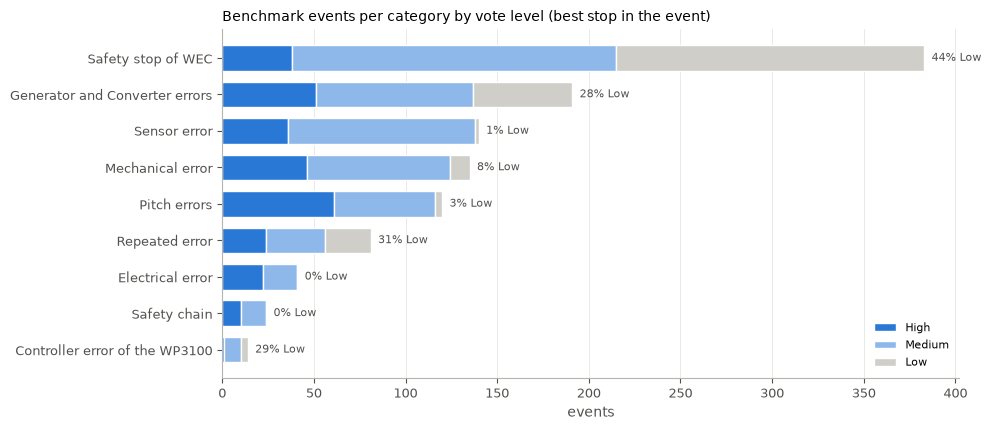

In [25]:
# Vote score per stop: -1 farm-wide, +1 service within SERVICE_DAYS, +1 comment; equal weight. Computed by
# pm.fault_stop_confidence so that population_form_penmanshiel.ipynb uses exactly the same labels.
VOTE_LEVELS = pm.CONFIDENCE_LEVELS
_keys = ["turbine_id", "timestamp_start", "code"]
_votes = pm.fault_stop_confidence(status)[_keys + ["vote_score", "confidence_rank"]]
fs = (fs.drop(columns=["vote_score", "vote_rank", "vote_level"], errors="ignore")
      .merge(_votes.rename(columns={"confidence_rank": "vote_rank"}), on=_keys, how="left", validate="one_to_one"))
fs["vote_level"] = fs["vote_rank"].map(VOTE_LEVELS)


def merge_events(stops_in, gap=pd.Timedelta(hours=24)):
    """Benchmark-style events: stops on one turbine within `gap` merge; the event takes the category of its longest
    stop and the best (highest) vote_rank of its stops."""
    out = []
    for t, g in stops_in[stops_in["timestamp_end"].notna()].sort_values("timestamp_start").groupby("turbine_id"):
        cur = None
        for r in g.itertuples(index=False):
            if cur is not None and r.timestamp_start <= cur["end"] + gap:
                cur["end"] = max(cur["end"], r.timestamp_end)
                cur["stops"] += 1
                cur["rank"] = max(cur["rank"], r.vote_rank)
                if r.minutes > cur["longest"]:
                    cur.update(longest=r.minutes, category=r.category)
            else:
                if cur is not None:
                    out.append(cur)
                cur = dict(turbine=t, start=r.timestamp_start, end=r.timestamp_end, stops=1, longest=r.minutes,
                           category=r.category, rank=r.vote_rank)
        out.append(cur)
    e = pd.DataFrame(out)
    e["hours"] = (e["end"] - e["start"]) / pd.Timedelta("1h")
    e["level"] = e["rank"].map(VOTE_LEVELS)
    return e


vote_events = merge_events(fs)
kept_events = merge_events(fs[fs["vote_rank"] > 1])

print("Stops by score:", fs["vote_score"].value_counts().sort_index().to_dict())
summary = pd.DataFrame({
    "stops": fs["vote_level"].value_counts(), "stop hours": fs.groupby("vote_level")["hours"].sum(),
    "events (by best stop)": vote_events["level"].value_counts()}).reindex(list(VOTE_LEVELS.values()))
summary.loc["Total"] = summary.sum()
display(summary.assign(**{"share of stops": summary["stops"] / len(fs),
                          "share of events": summary["events (by best stop)"] / len(vote_events)})
        .style.format({"stop hours": "{:,.0f}", "share of stops": "{:.0%}", "share of events": "{:.0%}"}))

# What excluding Low stops removes, per category (event category = longest stop, so it can change on re-merging).
def _per_cat(stops_in, events):
    return pd.DataFrame({"stops": stops_in.groupby("category").size(), "hours": stops_in.groupby("category")["hours"].sum(),
                         "events": events.groupby("category").size()})
before, after = _per_cat(fs, vote_events), _per_cat(fs[fs["vote_rank"] > 1], kept_events)
removed = before.join(after.reindex(before.index).astype(float).fillna(0.0).add_suffix(" kept"))
for c in ["stops", "hours", "events"]:
    removed[f"{c} removed"] = 1 - removed[f"{c} kept"] / removed[c]
removed = removed.sort_values("events", ascending=False)
removed.loc["All turbine faults"] = [*before.sum(), *after.sum(),
                                     *(1 - after.sum() / before.sum())]
print(f"Excluding Low stops removes {1 - len(fs[fs['vote_rank'] > 1]) / len(fs):.0%} of stops, "
      f"{1 - fs.loc[fs['vote_rank'] > 1, 'hours'].sum() / fs['hours'].sum():.0%} of stop hours and "
      f"{1 - len(kept_events) / len(vote_events):.0%} of events ({len(vote_events):,} -> {len(kept_events):,})")
display(removed[["stops", "stops kept", "stops removed", "hours", "hours removed", "events", "events kept", "events removed"]]
        .style.format({"hours": "{:,.0f}", "stops removed": "{:.0%}", "hours removed": "{:.0%}",
                       "events removed": "{:.0%}", "stops kept": "{:.0f}", "events kept": "{:.0f}"})
        .background_gradient(subset=["events removed"], cmap="Blues", vmin=0, vmax=1))

# Agreement with the code-by-code review above: vote level of stops against LABEL_REVIEW confidence.
print("Stops: vote level (columns) against the code review's confidence (rows)")
display(pd.crosstab(fs["confidence"], fs["vote_level"]).reindex(index=CONFIDENCE, columns=list(VOTE_LEVELS.values()),
                                                                   fill_value=0))

# Events per category by vote level.
lv = pd.crosstab(vote_events["category"], vote_events["level"]).reindex(columns=list(VOTE_LEVELS.values()), fill_value=0)
lv = lv[lv.sum(axis=1) >= 10]
lv = lv.loc[lv.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(10, 4.4))
left = np.zeros(len(lv))
for col, colr in zip(["High", "Medium", "Low"], [PALETTE[0], "#8fb8ea", "#cfcec8"]):
    ax.barh(range(len(lv)), lv[col], left=left, color=colr, height=0.7, label=col, edgecolor="white", linewidth=1)
    left += lv[col].to_numpy()
for i, (n, low) in enumerate(zip(lv.sum(axis=1), lv["Low"])):
    ax.text(n + 4, i, f"{low / n:.0%} Low", va="center", fontsize=8, color=MUTED)
ax.set_yticks(range(len(lv)), lv.index, fontsize=9)
ax.set_xlabel("events", color=MUTED)
ax.set_title("Benchmark events per category by vote level (best stop in the event)", loc="left", fontsize=10)
ax.legend(fontsize=8, frameon=False, loc="lower right")
style_ax(ax, grid_axis="x")
fig.tight_layout()
plt.show()

## Notes

- **Events and labels:** *Turbine fault* Stop events, with their start and end times, can serve as fault windows, much as CARE to Compare labels the period before an anomaly event. Short fault stops (a few minutes, auto-reset) are frequent and probably not useful as labels; filter by duration.
- **Logging change:** status rows are not comparable in count across the 2018 change; use Stop durations instead.
- **Commissioning:** data before 2016-09-01 is commissioning (long safety-chain and manual stops, gaps). Exclude it from training and evaluation.
- **Farm-wide stops:** grid and park-master stops affect all turbines at once and are not turbine faults, but they should be excluded from "normal" training data.
- **Label quality:** about 60% of turbine-fault events rest only on start-up, storm-protection or meta-codes (see *Fault labels*). Filter on the `confidence` from `LABEL_REVIEW` before using them as ground truth.